In [1]:
%load_ext autoreload 
%autoreload 2 

# Decision vs. Paragraph Level

## 0. Set Up

In [31]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

from network_pluralism.access.resolved import to_level
from network_pluralism.access.projected import to_projection
from network_pluralism.setup.params import (
    DEFAULT_COLOR,
    HIGHLIGHT_COLOR_DARK,
)

In [32]:
def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": True,
        "font.family": "serif",
        #"text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}\usepackage{amsfonts}\usepackage{lmodern}",
        "font.size": 12,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

In [33]:
EXPORT_PATH = Path("../../figures/decision_vs_paragraph")
EXPORT_PATH.mkdir(parents=True, exist_ok=True)

## 1. Computation

In [21]:
procedural_norms = [
    "vwgo_154",
    "zpo_563",
    "fgo_126",
    "gg_3",
    "zpo_97",
    "fgo_135",
    "zpo_562",
    "vwgo_137",
    "gkg_2004_52" ,
    "gg_2",
    "gg_103" ,
    "sgg_193",
    "sgg_170",
    "stpo_349",
    "vwgo_132",
]

In [22]:
threshold_para = 10
threshold_dec = 10

### a) Data

In [23]:
m_para, r, c = to_level(3, 1)
m_projection_para = to_projection(m_para)
m_projection_para.setdiag(0)
m_projection_para.eliminate_zeros()

m_dec, r, c = to_level(2, 1)
m_projection_dec = to_projection(m_dec)
m_projection_dec.setdiag(0)
m_projection_dec.eliminate_zeros()

Out Matrix of shape (3111483, 93645)
Out Matrix of shape (74214, 93645)


In [24]:
coo = m_projection_para.tocoo()
pairs_para_df = pd.DataFrame(zip(coo.row, coo.col, coo.data), columns=["id_left", "id_right", "count"])
pairs_para_df = pairs_para_df.merge(pd.DataFrame(c.items(), columns=["sem_id", "id"]), left_on="id_left", right_on="id")
pairs_para_df = pairs_para_df.merge(
    pd.DataFrame(c.items(), columns=["sem_id", "id"]), left_on="id_right", right_on="id"
)
pairs_para_df.sort_values(by="count", ascending=False)

,id_left,id_right,count,sem_id_x,id_x,sem_id_y,id_y
417097,92525,92526,3942.0,zpo_562,92525,zpo_563,92526
417634,92526,92525,3942.0,zpo_563,92526,zpo_562,92525
200878,37023,37015,3687.0,gkg_2004_52,37023,gkg_2004_47,37015
200599,37015,37023,3687.0,gkg_2004_47,37015,gkg_2004_52,37023
187508,36610,36517,2624.0,gg_2,36610,gg_1,36517
...,...,...,...,...,...,...,...
101550,13930,13595,1.0,bgb_634a,13930,bgb_433,13595
101549,13930,13548,1.0,bgb_634a,13930,bgb_390,13548
101548,13930,13489,1.0,bgb_634a,13930,bgb_346,13489
101547,13930,13431,1.0,bgb_634a,13930,bgb_314,13431


In [25]:
coo = m_projection_dec.tocoo()
pairs_dec_df = pd.DataFrame(zip(coo.row, coo.col, coo.data), columns=["id_left", "id_right", "count"])
pairs_dec_df = pairs_dec_df.merge(pd.DataFrame(c.items(), columns=["sem_id", "id"]), left_on="id_left", right_on="id")
pairs_dec_df = pairs_dec_df.merge(pd.DataFrame(c.items(), columns=["sem_id", "id"]), left_on="id_right", right_on="id")

In [26]:
merged_df = pd.merge(pairs_dec_df, pairs_para_df, on=["sem_id_x", "sem_id_y"], suffixes=["decision", "para"])[
    ["sem_id_x", "sem_id_y", "countdecision", "countpara"]
]  # .sample(5000)
merged_df = merged_df.query(f"countdecision>{threshold_dec} and countpara>{threshold_para}")

In [27]:
highlight_df = merged_df[merged_df["sem_id_x"].isin(procedural_norms) | merged_df["sem_id_y"].isin(procedural_norms)]
highlight_df

,sem_id_x,sem_id_y,countdecision,countpara
229,a_g_10,zpo_563,28.0,13.0
602,aa_g_1,gg_3,15.0,15.0
662,aa_g_6,gg_3,25.0,19.0
698,aa_g_7,gg_3,18.0,12.0
1366,aeg_1994_18,vwgo_132,86.0,18.0
...,...,...,...,...
429072,zpo_97,zpo_565,61.0,54.0
429096,zpo_97,zpo_91,649.0,560.0
429097,zpo_97,zpo_91a,75.0,49.0
429098,zpo_97,zpo_92,611.0,600.0


### b) Figures

In [28]:
upper_lim = 2000
lower_lim = 5

/var/folders/8k/r3s46h0143vflzq6wy9_001r0000gp/T/ipykernel_28116/1862467278.py:15: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, upper_lim)
/var/folders/8k/r3s46h0143vflzq6wy9_001r0000gp/T/ipykernel_28116/1862467278.py:16: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, upper_lim)


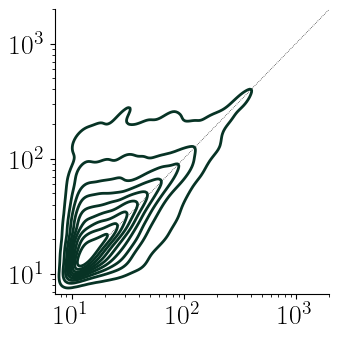

In [29]:
plt.figure(figsize=(3.5, 3.5))
sns.kdeplot(
    data=merged_df[~(merged_df["sem_id_x"].isin(procedural_norms) | merged_df["sem_id_y"].isin(procedural_norms))],
    x="countpara",
    y="countdecision",
    thresh=0.05,
    levels=10,
    fill=False,
    linewidths=2,
    ax=plt.gca(),
    zorder=3,
    log_scale=True,
    color=DEFAULT_COLOR,
)
plt.xlim(0, upper_lim)
plt.ylim(0, upper_lim)

# plt.tick_params('both',labelsiz=20)

plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.tick_params("both", labelsize=20)

x_line = np.linspace(0, upper_lim, 100)
plt.plot(x_line, x_line, color="black", linewidth=0.5, linestyle=":")
plt.savefig(EXPORT_PATH / "decision_vs_paragraph_all.pdf", dpi=300, transparent=True)

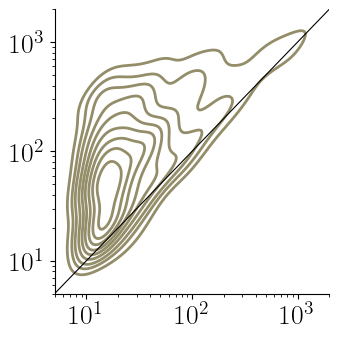

In [30]:
plt.figure(figsize=(3.5, 3.5))
sns.kdeplot(
    data=highlight_df,
    x="countpara",
    y="countdecision",
    thresh=0.1,
    levels=10,
    fill=False,
    
    linewidths=2,
    ax=plt.gca(),
    zorder=1,
    log_scale=True,
    color=HIGHLIGHT_COLOR_DARK,
)

plt.axline((1, 1), (upper_lim, upper_lim), color="black", linewidth=0.8)
plt.ylim(lower_lim, upper_lim)
plt.xlim(lower_lim, upper_lim)

plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.tick_params("both", labelsize=20)
plt.savefig(EXPORT_PATH / "decision_vs_paragraph_highlight.pdf", dpi=300, transparent=True)